# 14% — NoShow Predictor

**Full portfolio notebook:** dataset audit → leakage policy → temporal split → baselines → Logistic Regression / LightGBM → probability/risk evaluation → threshold & capacity analysis → subgroup audit → failure analysis → risk list → final package.

## Product question

> Given information available **before an appointment occurs**, estimate the risk that the appointment will become a no-show so reminders can be prioritized.

## Scope

This project predicts **appointment attendance risk**, not diagnosis, treatment outcome, patient health status, or clinical urgency.

## Evaluation protocol

- Target: `no_show` (`yes` = positive class)
- Primary selection metric: **Validation PR-AUC**
- Secondary metrics: ROC-AUC, Brier score, F1/F2, Precision, Recall
- Operational metric: **Recall / Precision / Lift in Top 10% highest-risk appointments**
- Split: **strictly temporal**
  - Train: up to `2020-12-31`
  - Validation: `2021-01-01` → `2021-09-30`
  - Held-out test: `2021-10-01` → `2022-02-25`
- Threshold: selected using validation only
- Test: used once after model and threshold decisions are locked

## Important leakage / ethics rules

Excluded from the champion model:

- `no_show_reason` — post-outcome leakage
- `icd` — sensitive diagnosis proxy
- `gender` — excluded from features; retained only for subgroup audit
- `city` — location/privacy proxy
- `disability` — sensitive attribute; audit only
- `date_of_birth` — raw personal date; not modeled directly
- same-day observed weather fields — may not be known at reminder time

The champion intentionally favors a narrower, operational feature set over maximizing benchmark score with questionable features.

In [1]:
import os, sys, time
print("=== NOSHOW PREDICTOR 14% — FULL PIPELINE BOOT ===", flush=True)
print("[BOOT] Python:", sys.version, flush=True)
print("[BOOT] cwd:", os.getcwd(), flush=True)
print("[BOOT] heartbeat 1", flush=True)
time.sleep(1)
print("[BOOT] heartbeat 2", flush=True)
with open("/kaggle/working/NOSHOW_14PCT_STARTED.txt", "w", encoding="utf-8") as f:
    f.write("started\n")
print("=== HEARTBEAT OK ===", flush=True)

=== NOSHOW PREDICTOR 14% — FULL PIPELINE BOOT ===
[BOOT] Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
[BOOT] cwd: /kaggle/working
[BOOT] heartbeat 1
[BOOT] heartbeat 2
=== HEARTBEAT OK ===


## 1. Environment and dependencies

In [2]:
import importlib.util, subprocess, sys

need=[]
if importlib.util.find_spec("lightgbm") is None:
    need.append("lightgbm")
if importlib.util.find_spec("sklearn") is None:
    need.append("scikit-learn")
if importlib.util.find_spec("joblib") is None:
    need.append("joblib")

if need:
    print("[SETUP] Installing:", need, flush=True)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *need])

print("[SETUP] dependencies OK", flush=True)

[SETUP] dependencies OK


In [3]:
from pathlib import Path
import json, random, shutil, warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss,
    precision_score, recall_score, f1_score, fbeta_score,
    confusion_matrix, precision_recall_curve, roc_curve,
    classification_report
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
SEED=42
random.seed(SEED)
np.random.seed(SEED)

DATA_ROOT = Path("/kaggle/input/datasets/wafabila/medical-appointments-no-show/Medical Appointments No-Show")
CSV_PATH = DATA_ROOT / "medical-appointments-no-show-en.csv"

if not CSV_PATH.exists():
    print("[PATH] canonical path not found; searching /kaggle/input ...", flush=True)
    candidates = list(Path("/kaggle/input").rglob("medical-appointments-no-show-en.csv"))
    if not candidates:
        raise FileNotFoundError("medical-appointments-no-show-en.csv not found")
    CSV_PATH = candidates[0]
    DATA_ROOT = CSV_PATH.parent

WORK = Path("/kaggle/working/noshow_14pct")
REPORTS = WORK / "reports"
MODELS = WORK / "models"
ASSET_DATA = WORK / "assets" / "dataset"
ASSET_TRAIN = WORK / "assets" / "training"
ASSET_EVAL = WORK / "assets" / "evaluation"
ASSET_PRED = WORK / "assets" / "predictions"

for p in [WORK, REPORTS, MODELS, ASSET_DATA, ASSET_TRAIN, ASSET_EVAL, ASSET_PRED]:
    p.mkdir(parents=True, exist_ok=True)

print("[PATH]", CSV_PATH)
assert CSV_PATH.exists()
print("=== INPUT CHECK PASSED ===", flush=True)

[PATH] /kaggle/input/datasets/wafabila/medical-appointments-no-show/Medical Appointments No-Show/medical-appointments-no-show-en.csv
=== INPUT CHECK PASSED ===


## 2. Load and inspect source data

In [4]:
df = pd.read_csv(CSV_PATH)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())
display(df.dtypes.to_frame("dtype"))

Shape: (49593, 26)
Columns: ['specialty', 'appointment_time', 'gender', 'appointment_date', 'no_show', 'no_show_reason', 'disability', 'date_of_birth', 'entry_service_date', 'city', 'icd', 'appointment_month', 'appointment_year', 'appointment_shift', 'age', 'under_12_years_old', 'over_60_years_old', 'patient_needs_companion', 'average_temp_day', 'average_rain_day', 'max_temp_day', 'max_rain_day', 'rainy_day_before', 'storm_day_before', 'rain_intensity', 'heat_intensity']


,specialty,appointment_time,gender,appointment_date,no_show,no_show_reason,disability,date_of_birth,entry_service_date,city,...,over_60_years_old,patient_needs_companion,average_temp_day,average_rain_day,max_temp_day,max_rain_day,rainy_day_before,storm_day_before,rain_intensity,heat_intensity
0,physiotherapy,13:20,M,09/09/2021,yes,surto,NaN,NaN,NaN,NaN,...,0,0,20.75,0.01,23.7,0.2,1,1,no_rain,mild
1,psychotherapy,13:20,M,09/09/2021,no,NaN,NaN,NaN,NaN,NaN,...,0,0,20.75,0.01,23.7,0.2,1,1,no_rain,mild
2,speech therapy,13:20,F,09/09/2021,no,NaN,NaN,NaN,NaN,NaN,...,0,0,20.75,0.01,23.7,0.2,1,1,no_rain,mild
3,physiotherapy,13:20,F,09/09/2021,no,NaN,NaN,NaN,NaN,NaN,...,0,0,20.75,0.01,23.7,0.2,1,1,no_rain,mild
4,physiotherapy,14:00,M,09/09/2021,no,NaN,motor,10/10/1954,5/2/2020,B. CAMBORIU,...,1,1,20.75,0.01,23.7,0.2,1,1,no_rain,mild


,dtype
specialty,object
appointment_time,object
gender,object
appointment_date,object
no_show,object
no_show_reason,object
disability,object
date_of_birth,object
entry_service_date,object
city,object


## 3. Source audit

In [5]:
EXPECTED = {
    "specialty","appointment_time","gender","appointment_date","no_show",
    "no_show_reason","disability","date_of_birth","entry_service_date","city",
    "icd","appointment_month","appointment_year","appointment_shift","age",
    "under_12_years_old","over_60_years_old","patient_needs_companion",
    "average_temp_day","average_rain_day","max_temp_day","max_rain_day",
    "rainy_day_before","storm_day_before","rain_intensity","heat_intensity"
}
assert EXPECTED.issubset(df.columns), EXPECTED - set(df.columns)

df["appointment_date_dt"] = pd.to_datetime(df["appointment_date"], dayfirst=True, errors="coerce")
assert df["appointment_date_dt"].notna().all()

df["target"] = df["no_show"].astype(str).str.lower().map({"no":0, "yes":1})
assert df["target"].notna().all()
df["target"] = df["target"].astype(int)

source_audit = {
    "rows": int(len(df)),
    "columns": int(len(df.columns)-2),
    "date_min": str(df["appointment_date_dt"].min().date()),
    "date_max": str(df["appointment_date_dt"].max().date()),
    "unique_dates": int(df["appointment_date_dt"].nunique()),
    "no_show_count": int(df["target"].sum()),
    "show_count": int((1-df["target"]).sum()),
    "no_show_rate": float(df["target"].mean()),
    "full_row_duplicates": int(df.drop(columns=["appointment_date_dt","target"]).duplicated().sum()),
    "missing_cells": int(df.drop(columns=["appointment_date_dt","target"]).isna().sum().sum()),
}

print(json.dumps(source_audit, indent=2))
(REPORTS / "source_audit.json").write_text(json.dumps(source_audit, indent=2), encoding="utf-8")

{
  "rows": 49593,
  "columns": 26,
  "date_min": "2016-06-20",
  "date_max": "2022-02-25",
  "unique_dates": 1001,
  "no_show_count": 4832,
  "show_count": 44761,
  "no_show_rate": 0.09743310547859577,
  "full_row_duplicates": 2921,
  "missing_cells": 134394
}


261

,missing,missing_rate
no_show_reason,47856,0.964975
icd,38876,0.783901
age,10350,0.208699
date_of_birth,10321,0.208114
specialty,7454,0.150303
city,5181,0.104470
entry_service_date,5155,0.103946
disability,5137,0.103583
average_temp_day,1016,0.020487
average_rain_day,1016,0.020487


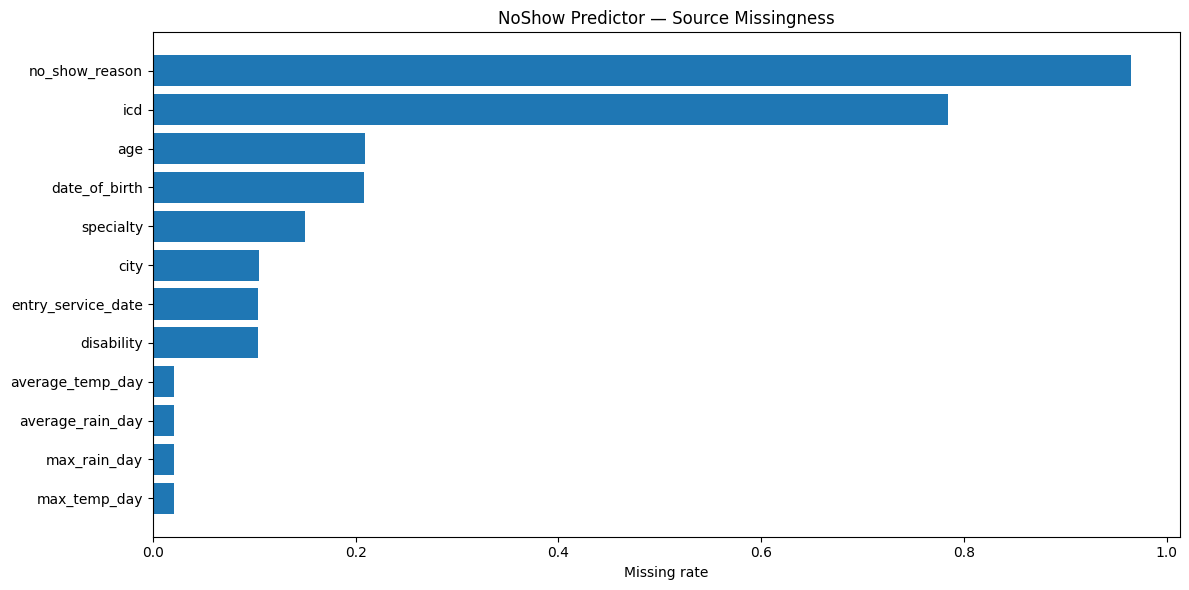

In [6]:
missing = (
    df.drop(columns=["appointment_date_dt","target"])
      .isna().sum()
      .sort_values(ascending=False)
      .rename("missing")
      .to_frame()
)
missing["missing_rate"] = missing["missing"] / len(df)
display(missing)
missing.to_csv(REPORTS / "missingness_report.csv")

plt.figure(figsize=(12,6))
m = missing[missing["missing"]>0].sort_values("missing_rate")
plt.barh(m.index, m["missing_rate"])
plt.xlabel("Missing rate")
plt.title("NoShow Predictor — Source Missingness")
plt.tight_layout()
plt.savefig(ASSET_DATA / "missingness.png", dpi=180, bbox_inches="tight")
plt.show()

### Duplicate policy

The source contains exact duplicate rows. **They are not automatically deleted.**

Reason: the dataset does not provide a stable patient ID or unique appointment ID. Two identical rows may represent separate appointments that happen to share the same recorded fields. Removing them blindly could destroy valid observations.

The duplicate count is therefore documented as a limitation rather than silently deduplicated.

## 4. Target leakage audit

In [7]:
leakage_audit = pd.DataFrame({
    "feature": [
        "no_show_reason", "icd", "gender", "city", "disability",
        "date_of_birth", "same-day weather", "appointment_date/time",
        "specialty", "age", "entry_service_date"
    ],
    "decision": [
        "EXCLUDE", "EXCLUDE", "EXCLUDE_FEATURE_USE_FOR_AUDIT", "EXCLUDE",
        "EXCLUDE_FEATURE_USE_FOR_AUDIT", "EXCLUDE_RAW", "EXCLUDE",
        "USE_DERIVED", "USE", "USE", "USE_DERIVED"
    ],
    "reason": [
        "post-outcome reason; direct leakage risk",
        "sensitive clinical diagnosis proxy",
        "sensitive demographic; retained only for subgroup audit",
        "location/privacy proxy and weak portability",
        "sensitive attribute; retained only for subgroup audit",
        "raw personal date; use age instead",
        "actual same-day weather may be unavailable at reminder time",
        "known operational scheduling information",
        "known service type before appointment",
        "available demographic age field; audit by age group",
        "derive service tenure when present"
    ]
})

display(leakage_audit)
leakage_audit.to_csv(REPORTS / "feature_policy.csv", index=False)

,feature,decision,reason
0,no_show_reason,EXCLUDE,post-outcome reason; direct leakage risk
1,icd,EXCLUDE,sensitive clinical diagnosis proxy
2,gender,EXCLUDE_FEATURE_USE_FOR_AUDIT,sensitive demographic; retained only for subgr...
3,city,EXCLUDE,location/privacy proxy and weak portability
4,disability,EXCLUDE_FEATURE_USE_FOR_AUDIT,sensitive attribute; retained only for subgrou...
5,date_of_birth,EXCLUDE_RAW,raw personal date; use age instead
6,same-day weather,EXCLUDE,actual same-day weather may be unavailable at ...
7,appointment_date/time,USE_DERIVED,known operational scheduling information
8,specialty,USE,known service type before appointment
9,age,USE,available demographic age field; audit by age ...


In [8]:
reason_by_target = (
    df.groupby("target")["no_show_reason"]
      .apply(lambda s: s.notna().mean())
      .rename("reason_nonnull_rate")
      .reset_index()
)
display(reason_by_target)

print("Top no-show reasons (audit only, never a feature):")
display(
    df.loc[df["target"]==1, "no_show_reason"]
      .value_counts(dropna=False)
      .head(20)
      .to_frame("count")
)

,target,reason_nonnull_rate
0,0,0.001340
1,1,0.347061


Top no-show reasons (audit only, never a feature):


,count
no_show_reason,
NaN,3155
doente,195
sem transporte,191
desmarcado,78
gripe,78
cancelado atendimento sexta feira,55
atestado,49
doença,47
remarcado,41


## 5. Temporal distribution and target drift

,month,appointments,no_show_rate
32,2019-04,584,0.125000
33,2019-05,462,0.140693
34,2019-06,454,0.114537
35,2019-07,780,0.134615
36,2019-08,799,0.103880
37,2019-09,1321,0.097653
38,2019-10,1907,0.111169
39,2019-11,867,0.119954
40,2019-12,21,0.095238
41,2020-03,156,0.192308


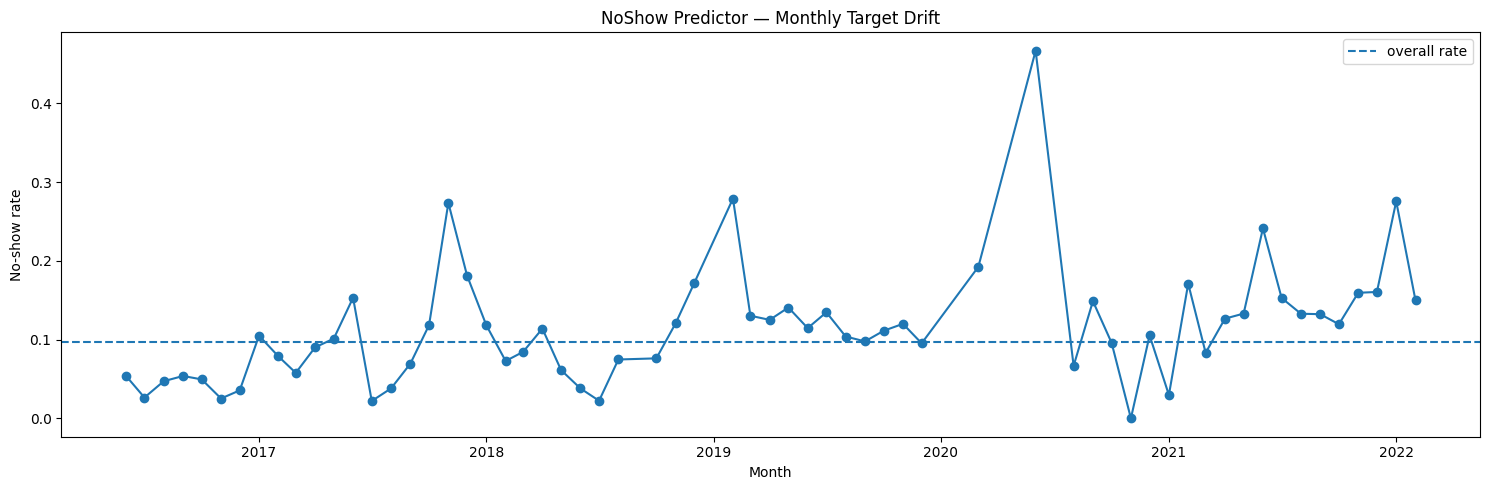

In [9]:
monthly = (
    df.assign(month=df["appointment_date_dt"].dt.to_period("M").astype(str))
      .groupby("month")
      .agg(appointments=("target","size"), no_show_rate=("target","mean"))
      .reset_index()
)
monthly.to_csv(REPORTS / "monthly_target_drift.csv", index=False)
display(monthly.tail(30))

plt.figure(figsize=(15,5))
plt.plot(pd.to_datetime(monthly["month"]), monthly["no_show_rate"], marker="o")
plt.axhline(df["target"].mean(), linestyle="--", label="overall rate")
plt.ylabel("No-show rate")
plt.xlabel("Month")
plt.title("NoShow Predictor — Monthly Target Drift")
plt.legend()
plt.tight_layout()
plt.savefig(ASSET_DATA / "monthly_no_show_rate.png", dpi=180, bbox_inches="tight")
plt.show()

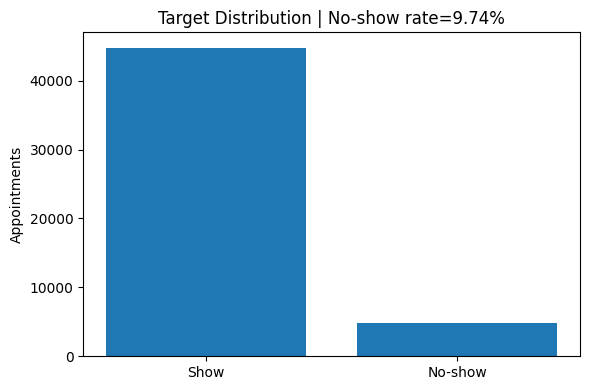

In [10]:
plt.figure(figsize=(6,4))
counts = df["target"].value_counts().sort_index()
plt.bar(["Show","No-show"], [counts.get(0,0), counts.get(1,0)])
plt.ylabel("Appointments")
plt.title(f"Target Distribution | No-show rate={df['target'].mean():.2%}")
plt.tight_layout()
plt.savefig(ASSET_DATA / "target_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. Feature engineering — pre-appointment information only

In [11]:
work = df.copy()

# Appointment time features.
time_parts = work["appointment_time"].astype(str).str.extract(r"(?P<hour>\d{1,2}):(?P<minute>\d{2})")
work["appointment_hour"] = pd.to_numeric(time_parts["hour"], errors="coerce")
work["appointment_minute"] = pd.to_numeric(time_parts["minute"], errors="coerce")

# Calendar features available from scheduled date.
work["appointment_dow"] = work["appointment_date_dt"].dt.dayofweek
work["appointment_day"] = work["appointment_date_dt"].dt.day
work["appointment_month_num"] = work["appointment_date_dt"].dt.month
work["appointment_year_num"] = work["appointment_date_dt"].dt.year
work["is_weekend"] = work["appointment_dow"].isin([5,6]).astype(int)
work["dow_sin"] = np.sin(2*np.pi*work["appointment_dow"]/7)
work["dow_cos"] = np.cos(2*np.pi*work["appointment_dow"]/7)
work["month_sin"] = np.sin(2*np.pi*work["appointment_month_num"]/12)
work["month_cos"] = np.cos(2*np.pi*work["appointment_month_num"]/12)

# Service tenure derived from entry_service_date, where available.
work["entry_service_dt"] = pd.to_datetime(work["entry_service_date"], dayfirst=True, errors="coerce")
work["service_tenure_days"] = (work["appointment_date_dt"] - work["entry_service_dt"]).dt.days
work.loc[work["service_tenure_days"] < 0, "service_tenure_days"] = np.nan

# Simple missingness indicators for operational fields.
work["specialty_missing"] = work["specialty"].isna().astype(int)
work["age_missing"] = work["age"].isna().astype(int)
work["tenure_missing"] = work["service_tenure_days"].isna().astype(int)

# Sensitive groups for audit only.
work["audit_age_group"] = pd.cut(
    work["age"], bins=[-np.inf,11,17,39,59,np.inf],
    labels=["0-11","12-17","18-39","40-59","60+"]
).astype(str)
work.loc[work["age"].isna(), "audit_age_group"] = "missing"

print("Feature-engineered shape:", work.shape)

Feature-engineered shape: (49593, 45)


## 7. Strict temporal split

In [12]:
TRAIN_END = pd.Timestamp("2020-12-31")
VAL_START = pd.Timestamp("2021-01-01")
VAL_END = pd.Timestamp("2021-09-30")
TEST_START = pd.Timestamp("2021-10-01")
TEST_END = pd.Timestamp("2022-02-25")

train = work[work["appointment_date_dt"] <= TRAIN_END].copy()
val = work[(work["appointment_date_dt"] >= VAL_START) & (work["appointment_date_dt"] <= VAL_END)].copy()
test = work[(work["appointment_date_dt"] >= TEST_START) & (work["appointment_date_dt"] <= TEST_END)].copy()

assert len(train) and len(val) and len(test)
assert train["appointment_date_dt"].max() < val["appointment_date_dt"].min()
assert val["appointment_date_dt"].max() < test["appointment_date_dt"].min()

split_summary = pd.DataFrame([
    {"split":"train","rows":len(train),"start":train["appointment_date_dt"].min(),"end":train["appointment_date_dt"].max(),"no_show_rate":train["target"].mean()},
    {"split":"validation","rows":len(val),"start":val["appointment_date_dt"].min(),"end":val["appointment_date_dt"].max(),"no_show_rate":val["target"].mean()},
    {"split":"test","rows":len(test),"start":test["appointment_date_dt"].min(),"end":test["appointment_date_dt"].max(),"no_show_rate":test["target"].mean()},
])

display(split_summary)
split_summary.to_csv(REPORTS / "temporal_split_summary.csv", index=False)

,split,rows,start,end,no_show_rate
0,train,39643,2016-06-20,2020-12-16,0.083470
1,validation,7243,2021-01-27,2021-09-24,0.150214
2,test,2707,2021-10-05,2022-02-25,0.160694


### Why temporal split?

A random split would mix older and future appointments. This project is intended for forward-looking operational use, so model selection must confront temporal drift rather than hide it.

## 8. Champion feature set

In [13]:
NUMERIC = [
    "age",
    "under_12_years_old",
    "over_60_years_old",
    "patient_needs_companion",
    "appointment_hour",
    "appointment_minute",
    "appointment_dow",
    "appointment_day",
    "appointment_month_num",
    "is_weekend",
    "dow_sin","dow_cos","month_sin","month_cos",
    "service_tenure_days",
    "specialty_missing","age_missing","tenure_missing",
]

CATEGORICAL = [
    "specialty",
    "appointment_shift",
]

FEATURES = NUMERIC + CATEGORICAL
TARGET = "target"

print("Numeric features:", NUMERIC)
print("Categorical features:", CATEGORICAL)

Numeric features: ['age', 'under_12_years_old', 'over_60_years_old', 'patient_needs_companion', 'appointment_hour', 'appointment_minute', 'appointment_dow', 'appointment_day', 'appointment_month_num', 'is_weekend', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'service_tenure_days', 'specialty_missing', 'age_missing', 'tenure_missing']
Categorical features: ['specialty', 'appointment_shift']


## 9. Baseline

In [14]:
def prob_metrics(y_true, prob, threshold=0.5):
    y_true=np.asarray(y_true, dtype=int)
    prob=np.asarray(prob, dtype=float)
    pred=(prob>=threshold).astype(int)
    return {
        "PR_AUC": float(average_precision_score(y_true, prob)),
        "ROC_AUC": float(roc_auc_score(y_true, prob)),
        "Brier": float(brier_score_loss(y_true, prob)),
        "Precision": float(precision_score(y_true, pred, zero_division=0)),
        "Recall": float(recall_score(y_true, pred, zero_division=0)),
        "F1": float(f1_score(y_true, pred, zero_division=0)),
        "F2": float(fbeta_score(y_true, pred, beta=2, zero_division=0)),
        "Threshold": float(threshold),
        "PredictedPositiveRate": float(pred.mean()),
        "N": int(len(y_true)),
    }


def top_fraction_metrics(y_true, prob, fraction=0.10):
    y_true=np.asarray(y_true, dtype=int)
    prob=np.asarray(prob, dtype=float)
    n=len(y_true)
    k=max(1, int(np.ceil(n*fraction)))
    order=np.argsort(-prob)
    selected=order[:k]
    tp=int(y_true[selected].sum())
    positives=int(y_true.sum())
    precision=tp/k
    recall=tp/positives if positives else np.nan
    base=positives/n if n else np.nan
    lift=precision/base if base>0 else np.nan
    return {
        "fraction": float(fraction), "k": int(k), "captured_no_shows": tp,
        "precision_at_capacity": float(precision), "recall_at_capacity": float(recall),
        "lift_vs_random": float(lift), "base_rate": float(base)
    }

train_rate=float(train[TARGET].mean())
val_baseline_prob=np.full(len(val), train_rate)
baseline_val = prob_metrics(val[TARGET], val_baseline_prob, threshold=train_rate)
baseline_capacity = top_fraction_metrics(val[TARGET], val_baseline_prob, 0.10)
print("Constant prevalence baseline:", baseline_val)
print("Capacity baseline:", baseline_capacity)

Constant prevalence baseline: {'PR_AUC': 0.1502139997238713, 'ROC_AUC': 0.5, 'Brier': 0.132104519584345, 'Precision': 0.1502139997238713, 'Recall': 1.0, 'F1': 0.2611931340775417, 'F2': 0.4691677447175507, 'Threshold': 0.08346996947758747, 'PredictedPositiveRate': 1.0, 'N': 7243}
Capacity baseline: {'fraction': 0.1, 'k': 725, 'captured_no_shows': 91, 'precision_at_capacity': 0.12551724137931033, 'recall_at_capacity': 0.08363970588235294, 'lift_vs_random': 0.8355895030425964, 'base_rate': 0.1502139997238713}


## 10. Logistic Regression baseline model

In [15]:
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), NUMERIC),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), CATEGORICAL),
])

logistic = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        C=1.0,
        random_state=SEED,
    )),
])

print("[TRAIN] Logistic Regression", flush=True)
logistic.fit(train[FEATURES], train[TARGET])
val_prob_log = logistic.predict_proba(val[FEATURES])[:,1]
log_val_metrics = prob_metrics(val[TARGET], val_prob_log, 0.5)
print(log_val_metrics)

[TRAIN] Logistic Regression
{'PR_AUC': 0.15033978380257235, 'ROC_AUC': 0.49821111781430694, 'Brier': 0.263577282212056, 'Precision': 0.14663951120162932, 'Recall': 0.5294117647058824, 'F1': 0.22966507177033493, 'F2': 0.34782608695652173, 'Threshold': 0.5, 'PredictedPositiveRate': 0.5423167195913295, 'N': 7243}


## 11. LightGBM candidates

In [16]:
def prepare_lgbm(frame):
    X=frame[FEATURES].copy()
    for c in CATEGORICAL:
        X[c]=X[c].fillna("__MISSING__").astype("category")
    for c in NUMERIC:
        X[c]=pd.to_numeric(X[c], errors="coerce")
    return X

X_train_lgb=prepare_lgbm(train)
X_val_lgb=prepare_lgbm(val)
y_train=train[TARGET].astype(int)
y_val=val[TARGET].astype(int)

pos=int(y_train.sum())
neg=int(len(y_train)-pos)
scale_pos=neg/max(pos,1)

candidate_params={
    "LGBM-Balanced": dict(
        objective="binary", n_estimators=500, learning_rate=0.035,
        num_leaves=31, min_child_samples=40, subsample=0.9,
        colsample_bytree=0.9, reg_alpha=0.10, reg_lambda=0.30,
        class_weight="balanced", random_state=SEED, n_jobs=-1, verbosity=-1,
    ),
    "LGBM-ScalePos": dict(
        objective="binary", n_estimators=500, learning_rate=0.035,
        num_leaves=31, min_child_samples=40, subsample=0.9,
        colsample_bytree=0.9, reg_alpha=0.10, reg_lambda=0.30,
        scale_pos_weight=scale_pos, random_state=SEED, n_jobs=-1, verbosity=-1,
    ),
    "LGBM-Unweighted": dict(
        objective="binary", n_estimators=500, learning_rate=0.035,
        num_leaves=31, min_child_samples=40, subsample=0.9,
        colsample_bytree=0.9, reg_alpha=0.10, reg_lambda=0.30,
        random_state=SEED, n_jobs=-1, verbosity=-1,
    ),
}

models={}
rows=[]
for name, params in candidate_params.items():
    print("[TRAIN]", name, flush=True)
    model=LGBMClassifier(**params)
    model.fit(X_train_lgb, y_train, categorical_feature=CATEGORICAL)
    prob=model.predict_proba(X_val_lgb)[:,1]
    met=prob_metrics(y_val, prob, 0.5)
    rows.append({"model":name, **met})
    models[name]=model

rows.append({"model":"Logistic-Balanced", **log_val_metrics})
validation_models=pd.DataFrame(rows).sort_values(["PR_AUC","ROC_AUC"], ascending=[False,False]).reset_index(drop=True)
display(validation_models)
validation_models.to_csv(REPORTS / "validation_model_comparison.csv", index=False)

[TRAIN] LGBM-Balanced
[TRAIN] LGBM-ScalePos
[TRAIN] LGBM-Unweighted


,model,PR_AUC,ROC_AUC,Brier,Precision,Recall,F1,F2,Threshold,PredictedPositiveRate,N
0,LGBM-Balanced,0.156092,0.506471,0.198662,0.166992,0.236213,0.195660,0.218129,0.5,0.212481,7243
1,LGBM-Unweighted,0.154455,0.517323,0.134153,0.166667,0.000919,0.001828,0.001147,0.5,0.000828,7243
2,LGBM-ScalePos,0.153355,0.500877,0.198229,0.146923,0.204044,0.170835,0.189323,0.5,0.208615,7243
3,Logistic-Balanced,0.150340,0.498211,0.263577,0.146640,0.529412,0.229665,0.347826,0.5,0.542317,7243


## 12. Champion selection

In [17]:
champion_name=validation_models.iloc[0]["model"]

if champion_name=="Logistic-Balanced":
    champion_family="logistic"
    champion_val_prob=val_prob_log
else:
    champion_family="lightgbm"
    champion_val_prob=models[champion_name].predict_proba(X_val_lgb)[:,1]

selection={
    "champion":champion_name,
    "family":champion_family,
    "selection_metric":"validation_PR_AUC",
    "validation_metrics_at_0.5":validation_models.iloc[0].to_dict(),
}
print(json.dumps(selection, indent=2, default=float))
(REPORTS / "model_selection.json").write_text(json.dumps(selection, indent=2, default=float), encoding="utf-8")

{
  "champion": "LGBM-Balanced",
  "family": "lightgbm",
  "selection_metric": "validation_PR_AUC",
  "validation_metrics_at_0.5": {
    "model": "LGBM-Balanced",
    "PR_AUC": 0.15609180853412816,
    "ROC_AUC": 0.5064712303483538,
    "Brier": 0.19866199152780203,
    "Precision": 0.16699155295646523,
    "Recall": 0.23621323529411764,
    "F1": 0.19566044918157594,
    "F2": 0.2181293498557121,
    "Threshold": 0.5,
    "PredictedPositiveRate": 0.21248101615352755,
    "N": 7243
  }
}


492

## 13. Validation-only threshold selection

Selected threshold: 0.44


,PR_AUC,ROC_AUC,Brier,Precision,Recall,F1,F2,Threshold,PredictedPositiveRate,N
1,0.156092,0.506471,0.198662,0.150118,0.996324,0.260922,0.468331,0.06,0.996963,7243
0,0.156092,0.506471,0.198662,0.149972,0.996324,0.260702,0.468048,0.05,0.997929,7243
3,0.156092,0.506471,0.198662,0.150475,0.990809,0.261270,0.468044,0.08,0.989093,7243
2,0.156092,0.506471,0.198662,0.150292,0.992647,0.261059,0.468019,0.07,0.992130,7243
4,0.156092,0.506471,0.198662,0.150414,0.985294,0.260986,0.466940,0.09,0.983985,7243
5,0.156092,0.506471,0.198662,0.150078,0.977022,0.260188,0.464801,0.10,0.977910,7243
6,0.156092,0.506471,0.198662,0.150071,0.969669,0.259916,0.463451,0.11,0.970592,7243
7,0.156092,0.506471,0.198662,0.149549,0.959559,0.258768,0.460602,0.12,0.963827,7243
8,0.156092,0.506471,0.198662,0.149130,0.945772,0.257636,0.457252,0.13,0.952644,7243
9,0.156092,0.506471,0.198662,0.149429,0.937500,0.257771,0.456253,0.14,0.942427,7243


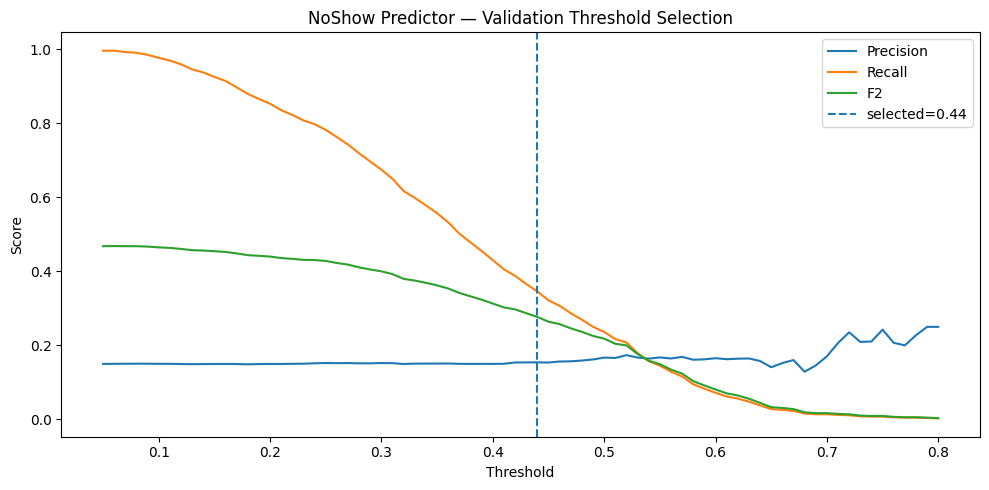

In [18]:
threshold_grid=np.round(np.arange(0.05,0.81,0.01),2)
threshold_rows=[]
for t in threshold_grid:
    threshold_rows.append(prob_metrics(val[TARGET], champion_val_prob, float(t)))
threshold_df=pd.DataFrame(threshold_rows)

# Reminder-prioritization MVP: favor recall using F2 while avoiding an absurdly large flagged population.
eligible=threshold_df[threshold_df["PredictedPositiveRate"] <= 0.35].copy()
if eligible.empty:
    eligible=threshold_df.copy()
selected=eligible.sort_values(["F2","Recall","Precision"], ascending=False).iloc[0]
selected_threshold=float(selected["Threshold"])

print("Selected threshold:", selected_threshold)
display(threshold_df.sort_values("F2", ascending=False).head(15))
threshold_df.to_csv(REPORTS / "validation_threshold_search.csv", index=False)

plt.figure(figsize=(10,5))
plt.plot(threshold_df["Threshold"], threshold_df["Precision"], label="Precision")
plt.plot(threshold_df["Threshold"], threshold_df["Recall"], label="Recall")
plt.plot(threshold_df["Threshold"], threshold_df["F2"], label="F2")
plt.axvline(selected_threshold, linestyle="--", label=f"selected={selected_threshold:.2f}")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("NoShow Predictor — Validation Threshold Selection")
plt.legend()
plt.tight_layout()
plt.savefig(ASSET_TRAIN / "validation_threshold_search.png", dpi=180, bbox_inches="tight")
plt.show()

## 14. Validation capacity analysis

,fraction,k,captured_no_shows,precision_at_capacity,recall_at_capacity,lift_vs_random,base_rate
0,0.05,363,58,0.159780,0.053309,1.063680,0.150214
1,0.10,725,120,0.165517,0.110294,1.101876,0.150214
2,0.15,1087,181,0.166513,0.166360,1.108507,0.150214
3,0.20,1449,240,0.165631,0.220588,1.102637,0.150214
4,0.25,1811,289,0.159580,0.265625,1.062353,0.150214
5,0.30,2173,338,0.155545,0.310662,1.035492,0.150214


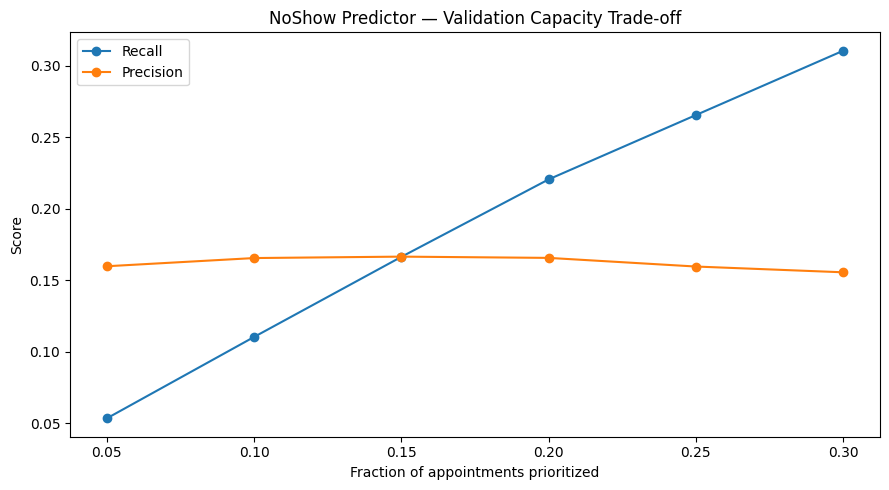

In [19]:
capacity_rows=[]
for fraction in [0.05,0.10,0.15,0.20,0.25,0.30]:
    capacity_rows.append(top_fraction_metrics(val[TARGET], champion_val_prob, fraction))
capacity_df=pd.DataFrame(capacity_rows)
display(capacity_df)
capacity_df.to_csv(REPORTS / "validation_capacity_analysis.csv", index=False)

plt.figure(figsize=(9,5))
plt.plot(capacity_df["fraction"], capacity_df["recall_at_capacity"], marker="o", label="Recall")
plt.plot(capacity_df["fraction"], capacity_df["precision_at_capacity"], marker="o", label="Precision")
plt.xlabel("Fraction of appointments prioritized")
plt.ylabel("Score")
plt.title("NoShow Predictor — Validation Capacity Trade-off")
plt.legend()
plt.tight_layout()
plt.savefig(ASSET_TRAIN / "validation_capacity_tradeoff.png", dpi=180, bbox_inches="tight")
plt.show()

## 15. Refit champion on Train + Validation

In [20]:
trainval=pd.concat([train,val], ignore_index=True).sort_values("appointment_date_dt")

if champion_family=="logistic":
    champion=clone(logistic)
    champion.fit(trainval[FEATURES], trainval[TARGET])
else:
    champion=LGBMClassifier(**candidate_params[champion_name])
    X_trainval_lgb=prepare_lgbm(trainval)
    champion.fit(X_trainval_lgb, trainval[TARGET], categorical_feature=CATEGORICAL)

MODEL_PATH=MODELS / "noshow_champion.joblib"
joblib.dump(champion, MODEL_PATH)
print("[MODEL] saved:", MODEL_PATH)

[MODEL] saved: /kaggle/working/noshow_14pct/models/noshow_champion.joblib


## 16. Official held-out test

In [21]:
if champion_family=="logistic":
    test_prob=champion.predict_proba(test[FEATURES])[:,1]
else:
    X_test_lgb=prepare_lgbm(test)
    test_prob=champion.predict_proba(X_test_lgb)[:,1]

test_metrics=prob_metrics(test[TARGET], test_prob, selected_threshold)
test_capacity10=top_fraction_metrics(test[TARGET], test_prob, 0.10)

print("=== OFFICIAL TEST METRICS ===")
print(json.dumps(test_metrics, indent=2))
print("=== TOP 10% CAPACITY ===")
print(json.dumps(test_capacity10, indent=2))

official_test={
    "champion":champion_name,
    "selected_threshold_from_validation":selected_threshold,
    "test_metrics":test_metrics,
    "top10_capacity":test_capacity10,
    "test_period":[str(TEST_START.date()), str(TEST_END.date())],
}
(REPORTS / "official_test_metrics.json").write_text(json.dumps(official_test, indent=2), encoding="utf-8")

=== OFFICIAL TEST METRICS ===
{
  "PR_AUC": 0.18193189164961232,
  "ROC_AUC": 0.5609038570503481,
  "Brier": 0.2522836700038834,
  "Precision": 0.17938931297709923,
  "Recall": 0.7563218390804598,
  "F1": 0.2899955927721463,
  "F2": 0.46026860660324564,
  "Threshold": 0.44,
  "PredictedPositiveRate": 0.6775027705947544,
  "N": 2707
}
=== TOP 10% CAPACITY ===
{
  "fraction": 0.1,
  "k": 271,
  "captured_no_shows": 49,
  "precision_at_capacity": 0.18081180811808117,
  "recall_at_capacity": 0.11264367816091954,
  "lift_vs_random": 1.1251898036221741,
  "base_rate": 0.1606944957517547
}


751

## 17. Test curves and confusion matrix

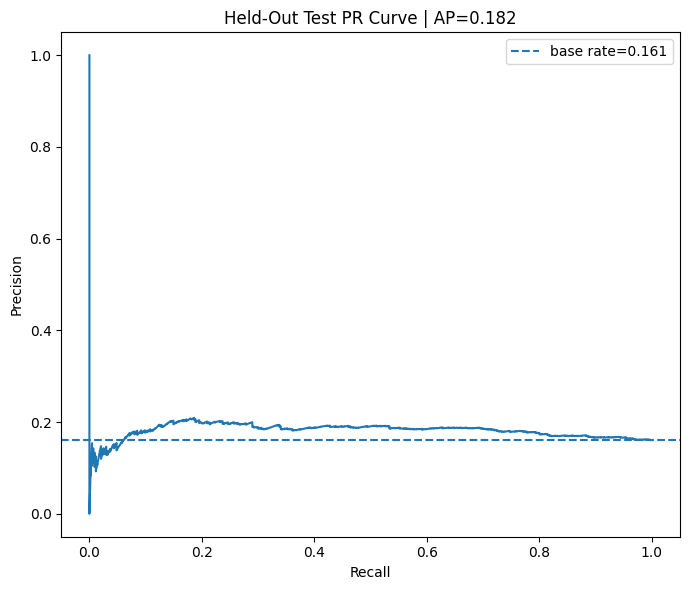

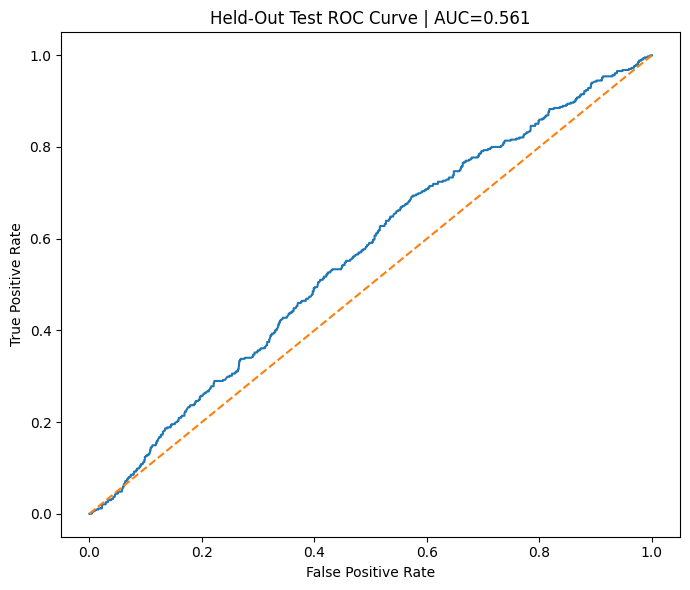

In [22]:
y_test=test[TARGET].to_numpy()

precision, recall, _ = precision_recall_curve(y_test, test_prob)
plt.figure(figsize=(7,6))
plt.plot(recall, precision)
plt.axhline(y_test.mean(), linestyle="--", label=f"base rate={y_test.mean():.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Held-Out Test PR Curve | AP={test_metrics['PR_AUC']:.3f}")
plt.legend()
plt.tight_layout()
plt.savefig(ASSET_EVAL / "test_pr_curve.png", dpi=180, bbox_inches="tight")
plt.show()

fpr,tpr,_=roc_curve(y_test,test_prob)
plt.figure(figsize=(7,6))
plt.plot(fpr,tpr)
plt.plot([0,1],[0,1],"--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"Held-Out Test ROC Curve | AUC={test_metrics['ROC_AUC']:.3f}")
plt.tight_layout()
plt.savefig(ASSET_EVAL / "test_roc_curve.png", dpi=180, bbox_inches="tight")
plt.show()

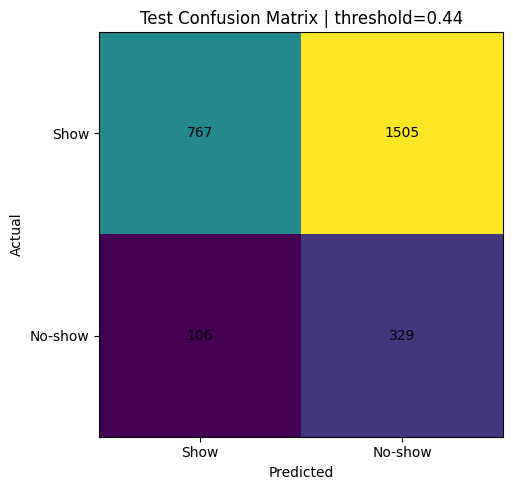

In [23]:
test_pred=(test_prob>=selected_threshold).astype(int)
cm=confusion_matrix(y_test,test_pred)

fig,ax=plt.subplots(figsize=(6,5))
im=ax.imshow(cm)
for i in range(2):
    for j in range(2):
        ax.text(j,i,str(cm[i,j]),ha="center",va="center")
ax.set_xticks([0,1], ["Show","No-show"])
ax.set_yticks([0,1], ["Show","No-show"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Test Confusion Matrix | threshold={selected_threshold:.2f}")
plt.tight_layout()
plt.savefig(ASSET_EVAL / "test_confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()

## 18. Test prediction table and risk list

In [24]:
test_out = test[[
    "appointment_date_dt","appointment_time","specialty","appointment_shift",
    "age","gender","disability","target"
]].copy()
test_out["risk_score"] = test_prob
test_out["predicted_no_show"] = test_pred
test_out["error_type"] = np.select(
    [
        (test_out["target"]==1)&(test_out["predicted_no_show"]==1),
        (test_out["target"]==0)&(test_out["predicted_no_show"]==1),
        (test_out["target"]==1)&(test_out["predicted_no_show"]==0),
    ],
    ["TP","FP","FN"],
    default="TN"
)
test_out.to_csv(REPORTS / "test_predictions.csv", index=False)

risk_list = test_out.sort_values("risk_score", ascending=False).reset_index(drop=True)
risk_list["priority_rank"] = np.arange(1, len(risk_list)+1)
risk_list["top_10_percent"] = risk_list["priority_rank"] <= int(np.ceil(len(risk_list)*0.10))
risk_list.to_csv(REPORTS / "test_risk_list.csv", index=False)

display(risk_list.head(30))

,appointment_date_dt,appointment_time,specialty,appointment_shift,age,gender,disability,target,risk_score,predicted_no_show,error_type,priority_rank,top_10_percent
0,2022-02-09,11:00,NaN,morning,10.0,F,intellectual,0,0.853476,1,FP,1,True
1,2022-02-09,08:40,NaN,morning,9.0,M,intellectual,0,0.812879,1,FP,2,True
2,2022-02-16,11:00,NaN,morning,10.0,F,intellectual,0,0.811444,1,FP,3,True
3,2022-02-09,09:20,NaN,morning,9.0,M,intellectual,0,0.808171,1,FP,4,True
4,2022-02-25,17:00,physiotherapy,afternoon,NaN,M,NaN,0,0.781214,1,FP,5,True
5,2022-02-25,17:00,physiotherapy,afternoon,NaN,M,NaN,0,0.781214,1,FP,6,True
6,2022-02-25,17:00,physiotherapy,afternoon,NaN,M,NaN,0,0.781214,1,FP,7,True
7,2022-02-25,17:00,physiotherapy,afternoon,NaN,M,NaN,0,0.781214,1,FP,8,True
8,2022-02-09,10:20,NaN,morning,10.0,F,intellectual,0,0.777191,1,FP,9,True
9,2022-02-16,08:40,NaN,morning,9.0,M,intellectual,1,0.775192,1,TP,10,True


## 19. Failure analysis

In [25]:
false_negatives = risk_list[risk_list["error_type"]=="FN"].sort_values("risk_score").head(30)
false_positives = risk_list[risk_list["error_type"]=="FP"].sort_values("risk_score", ascending=False).head(30)

false_negatives.to_csv(REPORTS / "false_negatives.csv", index=False)
false_positives.to_csv(REPORTS / "false_positives.csv", index=False)

print("False negatives — missed no-shows")
display(false_negatives.head(15))
print("False positives — unnecessary reminders")
display(false_positives.head(15))

False negatives — missed no-shows


,appointment_date_dt,appointment_time,specialty,appointment_shift,age,gender,disability,target,risk_score,predicted_no_show,error_type,priority_rank,top_10_percent
2701,2021-12-05,16:20,occupational therapy,afternoon,9.0,M,intellectual,1,0.138215,0,FN,2702,False
2689,2021-12-05,16:20,psychotherapy,afternoon,11.0,M,motor,1,0.181443,0,FN,2690,False
2675,2021-12-05,15:20,speech therapy,afternoon,9.0,M,intellectual,1,0.207756,0,FN,2676,False
2667,2021-10-29,15:10,physiotherapy,afternoon,39.0,M,motor,1,0.218150,0,FN,2668,False
2660,2021-11-03,08:00,NaN,morning,NaN,M,NaN,1,0.225014,0,FN,2661,False
2650,2022-02-01,07:20,psychotherapy,morning,NaN,F,NaN,1,0.232569,0,FN,2651,False
2646,2021-12-05,14:40,psychotherapy,afternoon,9.0,M,intellectual,1,0.236176,0,FN,2647,False
2643,2021-10-29,13:10,speech therapy,afternoon,5.0,M,intellectual,1,0.241166,0,FN,2644,False
2640,2021-11-03,07:20,NaN,morning,NaN,M,NaN,1,0.243637,0,FN,2641,False
2633,2022-02-02,08:40,NaN,morning,NaN,F,NaN,1,0.250310,0,FN,2634,False


False positives — unnecessary reminders


,appointment_date_dt,appointment_time,specialty,appointment_shift,age,gender,disability,target,risk_score,predicted_no_show,error_type,priority_rank,top_10_percent
0,2022-02-09,11:00,NaN,morning,10.0,F,intellectual,0,0.853476,1,FP,1,True
1,2022-02-09,08:40,NaN,morning,9.0,M,intellectual,0,0.812879,1,FP,2,True
2,2022-02-16,11:00,NaN,morning,10.0,F,intellectual,0,0.811444,1,FP,3,True
3,2022-02-09,09:20,NaN,morning,9.0,M,intellectual,0,0.808171,1,FP,4,True
4,2022-02-25,17:00,physiotherapy,afternoon,NaN,M,NaN,0,0.781214,1,FP,5,True
5,2022-02-25,17:00,physiotherapy,afternoon,NaN,M,NaN,0,0.781214,1,FP,6,True
7,2022-02-25,17:00,physiotherapy,afternoon,NaN,M,NaN,0,0.781214,1,FP,8,True
6,2022-02-25,17:00,physiotherapy,afternoon,NaN,M,NaN,0,0.781214,1,FP,7,True
8,2022-02-09,10:20,NaN,morning,10.0,F,intellectual,0,0.777191,1,FP,9,True
10,2022-02-25,16:20,speech therapy,afternoon,NaN,M,NaN,0,0.770863,1,FP,11,True


## 20. Subgroup audit — monitoring, not feature use

In [26]:
def subgroup_table(frame, probs, group_col, min_n=30):
    tmp=frame[[group_col,TARGET]].copy()
    tmp["prob"]=probs
    tmp[group_col]=tmp[group_col].fillna("missing").astype(str)
    rows=[]
    for group,g in tmp.groupby(group_col):
        if len(g)<min_n or g[TARGET].nunique()<2:
            continue
        m=prob_metrics(g[TARGET], g["prob"], selected_threshold)
        rows.append({"group":group,"n":len(g),"positive_rate":g[TARGET].mean(), **m})
    return pd.DataFrame(rows)

gender_audit=subgroup_table(test.assign(gender=test["gender"]), test_prob, "gender", 20)
age_audit=subgroup_table(test.assign(audit_age_group=test["audit_age_group"]), test_prob, "audit_age_group", 20)
disability_audit=subgroup_table(test.assign(disability=test["disability"]), test_prob, "disability", 20)

print("Gender audit")
display(gender_audit)
print("Age audit")
display(age_audit)
print("Disability audit")
display(disability_audit)

gender_audit.to_csv(REPORTS / "subgroup_gender_audit.csv", index=False)
age_audit.to_csv(REPORTS / "subgroup_age_audit.csv", index=False)
disability_audit.to_csv(REPORTS / "subgroup_disability_audit.csv", index=False)

Gender audit


,group,n,positive_rate,PR_AUC,ROC_AUC,Brier,Precision,Recall,F1,F2,Threshold,PredictedPositiveRate,N
0,F,573,0.193717,0.230043,0.556735,0.266550,0.205689,0.846847,0.330986,0.521643,0.44,0.797557,573
1,M,2134,0.151828,0.170167,0.557870,0.248453,0.170661,0.725309,0.276308,0.439581,0.44,0.645267,2134


Age audit


,group,n,positive_rate,PR_AUC,ROC_AUC,Brier,Precision,Recall,F1,F2,Threshold,PredictedPositiveRate,N
0,0-11,700,0.135714,0.199779,0.613589,0.210072,0.181818,0.610526,0.280193,0.414878,0.44,0.455714,700
1,12-17,86,0.220930,0.413406,0.622545,0.192253,0.300000,0.315789,0.307692,0.312500,0.44,0.232558,86
2,18-39,61,0.278689,0.237505,0.402406,0.266094,0.250000,0.588235,0.350877,0.462963,0.44,0.655738,61
3,40-59,22,0.272727,0.821429,0.864583,0.177138,0.500000,0.666667,0.571429,0.625000,0.44,0.363636,22
4,60+,53,0.132075,0.131412,0.468944,0.191255,0.058824,0.142857,0.083333,0.111111,0.44,0.320755,53
5,missing,1785,0.163025,0.174584,0.543583,0.273996,0.174825,0.859107,0.290529,0.481881,0.44,0.801120,1785


Disability audit


,group,n,positive_rate,PR_AUC,ROC_AUC,Brier,Precision,Recall,F1,F2,Threshold,PredictedPositiveRate,N
0,intellectual,805,0.139130,0.211197,0.617431,0.205325,0.186589,0.571429,0.281319,0.404551,0.44,0.426087,805
1,missing,1755,0.164672,0.174312,0.538438,0.275325,0.175265,0.858131,0.291080,0.482303,0.44,0.806268,1755
2,motor,147,0.231293,0.219161,0.489589,0.234352,0.223684,0.500000,0.309091,0.400943,0.44,0.517007,147


### Fairness interpretation

These subgroup tables are **monitoring diagnostics**, not proof of fairness. Small groups and temporal drift can make subgroup metrics unstable. Sensitive attributes are not used by the champion model merely because they are available in the source dataset.

## 21. Feature importance / coefficients

,feature,importance
14,service_tenure_days,3846
0,age,2463
7,appointment_day,2290
4,appointment_hour,1066
8,appointment_month_num,973
5,appointment_minute,778
6,appointment_dow,707
13,month_cos,702
12,month_sin,584
10,dow_sin,584


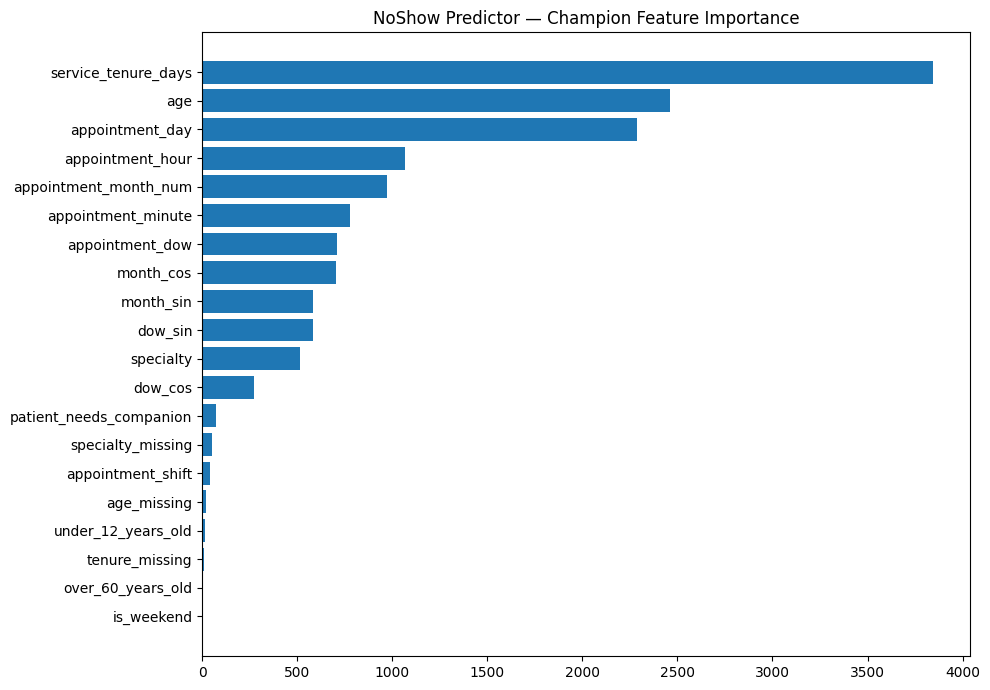

In [27]:
if champion_family=="lightgbm":
    importance=pd.DataFrame({
        "feature":FEATURES,
        "importance":champion.feature_importances_
    }).sort_values("importance", ascending=False)
    importance.to_csv(REPORTS / "feature_importance.csv", index=False)
    display(importance.head(25))

    plt.figure(figsize=(10,7))
    p=importance.head(20).sort_values("importance")
    plt.barh(p["feature"],p["importance"])
    plt.title("NoShow Predictor — Champion Feature Importance")
    plt.tight_layout()
    plt.savefig(ASSET_TRAIN / "feature_importance_top20.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    names=champion.named_steps["prep"].get_feature_names_out()
    coef=champion.named_steps["model"].coef_[0]
    importance=pd.DataFrame({"feature":names,"coefficient":coef})
    importance["abs_coefficient"]=importance["coefficient"].abs()
    importance=importance.sort_values("abs_coefficient", ascending=False)
    importance.to_csv(REPORTS / "logistic_coefficients.csv", index=False)
    display(importance.head(25))

## 22. Operational recommendation artifact

In [28]:
operational = {
    "purpose": "prioritize reminders, not automate punitive decisions",
    "review_owner": "service operations / scheduling staff",
    "selected_threshold": selected_threshold,
    "capacity_view": "Top 10% highest-risk appointments",
    "human_in_the_loop": True,
    "recommended_action": [
        "Use risk list to prioritize reminder outreach.",
        "Do not cancel or deprioritize appointments solely from model score.",
        "Review false-negative and subgroup metrics after deployment changes.",
        "Revalidate threshold if reminder capacity or prevalence changes."
    ]
}
(REPORTS / "operational_policy.json").write_text(json.dumps(operational, indent=2), encoding="utf-8")
print(json.dumps(operational, indent=2))

{
  "purpose": "prioritize reminders, not automate punitive decisions",
  "review_owner": "service operations / scheduling staff",
  "selected_threshold": 0.44,
  "capacity_view": "Top 10% highest-risk appointments",
  "human_in_the_loop": true,
  "recommended_action": [
    "Use risk list to prioritize reminder outreach.",
    "Do not cancel or deprioritize appointments solely from model score.",
    "Review false-negative and subgroup metrics after deployment changes.",
    "Revalidate threshold if reminder capacity or prevalence changes."
  ]
}


## 23. Model interface and reproducibility config

In [29]:
model_config={
    "project":"NoShow Predictor",
    "portfolio_progress":"14%",
    "task":"pre-appointment no-show risk classification",
    "positive_class":"no_show=yes",
    "features":FEATURES,
    "numeric_features":NUMERIC,
    "categorical_features":CATEGORICAL,
    "excluded_features":[
        "no_show_reason","icd","gender","city","disability","date_of_birth",
        "average_temp_day","average_rain_day","max_temp_day","max_rain_day",
        "rainy_day_before","storm_day_before","rain_intensity","heat_intensity"
    ],
    "champion":champion_name,
    "selected_threshold":selected_threshold,
    "selection_metric":"validation_PR_AUC",
    "train_end":str(TRAIN_END.date()),
    "validation_period":[str(VAL_START.date()),str(VAL_END.date())],
    "test_period":[str(TEST_START.date()),str(TEST_END.date())],
}
(REPORTS / "model_config.json").write_text(json.dumps(model_config, indent=2), encoding="utf-8")
print(json.dumps(model_config, indent=2))

{
  "project": "NoShow Predictor",
  "portfolio_progress": "14%",
  "task": "pre-appointment no-show risk classification",
  "positive_class": "no_show=yes",
  "features": [
    "age",
    "under_12_years_old",
    "over_60_years_old",
    "patient_needs_companion",
    "appointment_hour",
    "appointment_minute",
    "appointment_dow",
    "appointment_day",
    "appointment_month_num",
    "is_weekend",
    "dow_sin",
    "dow_cos",
    "month_sin",
    "month_cos",
    "service_tenure_days",
    "specialty_missing",
    "age_missing",
    "tenure_missing",
    "specialty",
    "appointment_shift"
  ],
  "numeric_features": [
    "age",
    "under_12_years_old",
    "over_60_years_old",
    "patient_needs_companion",
    "appointment_hour",
    "appointment_minute",
    "appointment_dow",
    "appointment_day",
    "appointment_month_num",
    "is_weekend",
    "dow_sin",
    "dow_cos",
    "month_sin",
    "month_cos",
    "service_tenure_days",
    "specialty_missing",
    "age_mi

## 24. Final source-of-truth summary

In [30]:
final_summary={
    "project":"NoShow Predictor",
    "portfolio_progress":"14%",
    "dataset":"Medical Appointments No-Show",
    "source_audit":source_audit,
    "problem_definition":{
        "task":"pre-appointment no-show risk prioritization",
        "positive_class":"no_show=yes",
        "intended_user":"scheduling / service operations staff",
        "intended_action":"prioritize reminders",
    },
    "temporal_split":{
        "train_end":str(TRAIN_END.date()),
        "validation":[str(VAL_START.date()),str(VAL_END.date())],
        "test":[str(TEST_START.date()),str(TEST_END.date())],
    },
    "model_selection":selection,
    "selected_threshold":selected_threshold,
    "official_test":official_test,
    "limitations":[
        "No stable patient identifier or appointment identifier is provided.",
        "Exact duplicate rows cannot safely be deduplicated without identity information.",
        "No booking-created timestamp is available, so appointment lead time cannot be modeled.",
        "The no-show base rate changes substantially over time.",
        "The dataset comes from a medical-service context and may not transfer to salons/studios.",
        "Risk score is not a clinical outcome and must not influence medical priority.",
        "Probability calibration is evaluated with Brier score but not guaranteed out-of-domain.",
    ],
    "claim_boundaries":{
        "supported":[
            "pre-appointment no-show risk estimation",
            "temporal held-out evaluation",
            "reminder-prioritization risk list",
            "validation-selected threshold",
            "Top-10%-capacity recall/precision/lift"
        ],
        "unsupported":[
            "clinical risk prediction",
            "diagnostic prediction",
            "patient blame or punitive action",
            "universal no-show probability across businesses",
            "automatic cancellation decisions"
        ]
    }
}
(REPORTS / "final_summary.json").write_text(json.dumps(final_summary, indent=2), encoding="utf-8")
print(json.dumps(final_summary, indent=2))

{
  "project": "NoShow Predictor",
  "portfolio_progress": "14%",
  "dataset": "Medical Appointments No-Show",
  "source_audit": {
    "rows": 49593,
    "columns": 26,
    "date_min": "2016-06-20",
    "date_max": "2022-02-25",
    "unique_dates": 1001,
    "no_show_count": 4832,
    "show_count": 44761,
    "no_show_rate": 0.09743310547859577,
    "full_row_duplicates": 2921,
    "missing_cells": 134394
  },
  "problem_definition": {
    "task": "pre-appointment no-show risk prioritization",
    "positive_class": "no_show=yes",
    "intended_user": "scheduling / service operations staff",
    "intended_action": "prioritize reminders"
  },
  "temporal_split": {
    "train_end": "2020-12-31",
    "validation": [
      "2021-01-01",
      "2021-09-30"
    ],
    "test": [
      "2021-10-01",
      "2022-02-25"
    ]
  },
  "model_selection": {
    "champion": "LGBM-Balanced",
    "family": "lightgbm",
    "selection_metric": "validation_PR_AUC",
    "validation_metrics_at_0.5": {
      

## 25. Package final portfolio artifacts

In [31]:
PACKAGE=Path("/kaggle/working/noshow_14pct_FINAL")
if PACKAGE.exists():
    shutil.rmtree(PACKAGE)

for p in [
    PACKAGE/"models", PACKAGE/"reports",
    PACKAGE/"assets"/"dataset", PACKAGE/"assets"/"training",
    PACKAGE/"assets"/"evaluation", PACKAGE/"assets"/"predictions"
]:
    p.mkdir(parents=True, exist_ok=True)

shutil.copy2(MODEL_PATH, PACKAGE/"models"/MODEL_PATH.name)
for src in REPORTS.glob("*"):
    if src.is_file():
        shutil.copy2(src, PACKAGE/"reports"/src.name)

for src_dir,dst_dir in [
    (ASSET_DATA,PACKAGE/"assets"/"dataset"),
    (ASSET_TRAIN,PACKAGE/"assets"/"training"),
    (ASSET_EVAL,PACKAGE/"assets"/"evaluation"),
    (ASSET_PRED,PACKAGE/"assets"/"predictions"),
]:
    for src in src_dir.glob("*"):
        if src.is_file():
            shutil.copy2(src,dst_dir/src.name)

zip_path=shutil.make_archive(
    "/kaggle/working/noshow_14pct_FINAL",
    "zip",
    root_dir=str(PACKAGE)
)

print("=== NOSHOW PREDICTOR 14% FINAL DONE ===", flush=True)
print("[DONE] Champion:", champion_name, flush=True)
print("[DONE] Selected threshold:", selected_threshold, flush=True)
print("[DONE] Test PR-AUC:", test_metrics["PR_AUC"], flush=True)
print("[DONE] Test ROC-AUC:", test_metrics["ROC_AUC"], flush=True)
print("[DONE] Test Recall:", test_metrics["Recall"], flush=True)
print("[DONE] Top10 Recall:", test_capacity10["recall_at_capacity"], flush=True)
print("[DONE] ZIP:", zip_path, flush=True)

=== NOSHOW PREDICTOR 14% FINAL DONE ===
[DONE] Champion: LGBM-Balanced
[DONE] Selected threshold: 0.44
[DONE] Test PR-AUC: 0.18193189164961232
[DONE] Test ROC-AUC: 0.5609038570503481
[DONE] Test Recall: 0.7563218390804598
[DONE] Top10 Recall: 0.11264367816091954
[DONE] ZIP: /kaggle/working/noshow_14pct_FINAL.zip


# Expected final output

```text
/kaggle/working/noshow_14pct_FINAL.zip
```

## Package structure

```text
noshow_14pct_FINAL/
├── models/
│   └── noshow_champion.joblib
├── reports/
│   ├── source_audit.json
│   ├── missingness_report.csv
│   ├── feature_policy.csv
│   ├── monthly_target_drift.csv
│   ├── temporal_split_summary.csv
│   ├── validation_model_comparison.csv
│   ├── model_selection.json
│   ├── validation_threshold_search.csv
│   ├── validation_capacity_analysis.csv
│   ├── official_test_metrics.json
│   ├── test_predictions.csv
│   ├── test_risk_list.csv
│   ├── false_negatives.csv
│   ├── false_positives.csv
│   ├── subgroup_*_audit.csv
│   ├── operational_policy.json
│   ├── model_config.json
│   └── final_summary.json
└── assets/
    ├── dataset/
    ├── training/
    ├── evaluation/
    └── predictions/
```

## Save Version checklist

- [ ] heartbeat appears immediately
- [ ] source path verified
- [ ] target mapping verified
- [ ] leakage policy documented
- [ ] no `no_show_reason` in model features
- [ ] temporal split printed
- [ ] target drift visualized
- [ ] Logistic Regression evaluated
- [ ] LightGBM candidates evaluated
- [ ] champion selected on validation PR-AUC only
- [ ] threshold selected on validation only
- [ ] Top-10% capacity analysis generated
- [ ] champion refit on Train + Validation
- [ ] held-out test evaluated once
- [ ] PR/ROC/confusion assets generated
- [ ] false negatives / false positives exported
- [ ] subgroup monitoring audit exported
- [ ] risk list exported
- [ ] final_summary.json written
- [ ] final ZIP exists